# Análise e Tratamento de Valores Ausentes em Dados Pluviométricos de Pernambuco

**Disciplina:** Ciência de Dados  
**Projeto:** Classificação de Mesorregiões de Pernambuco utilizando KNN  
**Responsável pela análise:** José Ricardo Veiga Monteiro Torres

## 1. Introdução

Este notebook tem como objetivo investigar os padrões de valores ausentes no conjunto de dados pluviométricos da Agência Pernambucana de Águas e Clima (APAC) e avaliar diferentes estratégias de tratamento dessas ausências.

O conjunto de dados contém registros anuais de postos pluviométricos de Pernambuco, com 12 atributos correspondentes aos totais mensais de precipitação.

A análise busca identificar possíveis padrões de ausência, discutir seus mecanismos estatísticos (MCAR, MAR e MNAR) e comparar métodos de imputação quanto ao desempenho de um classificador KNN.

A avaliação será realizada por meio de validação cruzada agrupada por posto pluviométrico, utilizando principalmente a métrica F1-macro.

**Objetivo final:** recomendar uma estratégia de tratamento de valores ausentes que preserve informações relevantes e apresente desempenho consistente na classificação das mesorregiões.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from pathlib import Path

arquivo = Path("data/raw/Dataset APAC - Página1.csv")

if not arquivo.exists():
    arquivo = Path("/content/Dataset APAC - Página1.csv")

if not arquivo.exists():
    raise FileNotFoundError(
        "Dataset não encontrado. Execute a partir da raiz "
        "do repositório ou envie o CSV ao Colab."
    )

df = pd.read_csv(arquivo)

print(f"Dataset carregado: {len(df)} registros")
df.head()

Dataset carregado: 5104 registros


,Código,Posto,Ano,Janeiro,Fevereiro,Março,Abril,Maio,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro,Meses ausentes
0,198,Abreu e Lima,2010,"83,5","44,4","69,2","188,4","142,8","258,4","158,4","43,7","52,2","15,9","10,1","46,4",0
1,290,Afogados da Ingazeira,2010,145,62,41,147,"1,5","74,7","17,5",-,-,"185,5",-,"29,5",3
2,377,Afogados da Ingazeira (Açude Brotas),2010,"120,2","58,5","30,5",122,"1,5","72,7","15,7",-,-,"162,2",-,"37,4",3
3,549,Afogados da Ingazeira - PCD,2010,-,-,-,-,-,"73,2","15,8","0,2","1,2","191,8",-,"28,4",6
4,1,Afrânio,2010,"84,6","9,7","69,9","193,5",-,"16,5","5,6",-,-,"20,3","7,6","192,7",3


In [30]:
import sys
from pathlib import Path

# Permitir importar os módulos da pasta src/ do repositório
if Path("src/data.py").exists():
    sys.path.insert(0, str(Path("src").resolve()))

try:
    from data import extrair_cidade
    from meso_map import meso_map

    print("Módulos importados com sucesso!")

except ModuleNotFoundError as erro:
    print(f"Erro ao importar módulos: {erro}")
    print("Verifique se data.py e meso_map.py estão disponíveis.")
    raise

Módulos importados com sucesso!


In [3]:
meses = [
    "Janeiro", "Fevereiro", "Março", "Abril",
    "Maio", "Junho", "Julho", "Agosto",
    "Setembro", "Outubro", "Novembro", "Dezembro"
]

for mes in meses:
    df[mes] = pd.to_numeric(
        df[mes].astype(str).str.replace(",", "."),
        errors="coerce"
    )

df[meses].head()


,Janeiro,Fevereiro,Março,Abril,Maio,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro
0,83.5,44.4,69.2,188.4,142.8,258.4,158.4,43.7,52.2,15.9,10.1,46.4
1,145.0,62.0,41.0,147.0,1.5,74.7,17.5,NaN,NaN,185.5,NaN,29.5
2,120.2,58.5,30.5,122.0,1.5,72.7,15.7,NaN,NaN,162.2,NaN,37.4
3,NaN,NaN,NaN,NaN,NaN,73.2,15.8,0.2,1.2,191.8,NaN,28.4
4,84.6,9.7,69.9,193.5,NaN,16.5,5.6,NaN,NaN,20.3,7.6,192.7


In [4]:
df["qtd_ausentes"] = df[meses].isna().sum(axis=1)

completas = (df["qtd_ausentes"] == 0).sum()
parciais = df["qtd_ausentes"].between(1, 11).sum()
vazias = (df["qtd_ausentes"] == 12).sum()

print(f"Linhas completas: {completas}")
print(f"Linhas parcialmente vazias: {parciais}")
print(f"Linhas totalmente vazias: {vazias}")
print(f"Total de registros: {len(df)}")

Linhas completas: 1461
Linhas parcialmente vazias: 2081
Linhas totalmente vazias: 1562
Total de registros: 5104


In [5]:
vazias_por_ano = (
    df[df["qtd_ausentes"] == 12]
    .groupby("Ano")
    .size()
    .reset_index(name="Linhas totalmente vazias")
)

display(vazias_por_ano)

,Ano,Linhas totalmente vazias
0,2010,100
1,2011,111
2,2012,133
3,2013,79
4,2014,96
5,2015,91
6,2016,87
7,2017,87
8,2018,89
9,2019,92


In [6]:
postos = df.groupby(["Código", "Posto"]).agg(
    total_registros=("Ano", "count"),
    registros_vazios=("qtd_ausentes", lambda x: (x == 12).sum())
).reset_index()

postos["sempre_vazio"] = (
    postos["total_registros"] == postos["registros_vazios"]
)

print("Total de postos:", len(postos))
print("Postos sempre vazios:", postos["sempre_vazio"].sum())

display(postos[postos["sempre_vazio"]])

Total de postos: 319
Postos sempre vazios: 12


,Código,Posto,total_registros,registros_vazios,sempre_vazio
4,5,Ouricuri,16,16,True
9,10,Belém de São Francisco,16,16,True
14,15,São José do Belmonte (Bom Nome),16,16,True
22,23,Lajedo,16,16,True
28,29,Ipojuca (Porto de Galinhas - IPA),16,16,True
35,39,Salgueiro (CHESF),16,16,True
37,45,Sertânia (CHESF),16,16,True
38,46,Custódia (CHESF),16,16,True
55,73,Vertentes,16,16,True
119,150,Pedra,16,16,True


In [7]:
# Selecionar apenas registros parcialmente vazios
df_parciais = df[df["qtd_ausentes"].between(1, 11)].copy()

# Calcular a porcentagem de ausências por mês
percentual_ausentes = (
    df_parciais[meses].isna().mean() * 100
)

# Organizar os resultados
tabela_ausentes = pd.DataFrame({
    "Mês": meses,
    "Ausentes (%)": percentual_ausentes.values
})

display(tabela_ausentes.round(2))

,Mês,Ausentes (%)
0,Janeiro,19.17
1,Fevereiro,17.35
2,Março,9.27
3,Abril,11.97
4,Maio,13.60
5,Junho,17.64
6,Julho,19.41
7,Agosto,35.08
8,Setembro,48.97
9,Outubro,47.33


In [38]:
df["Cidade"] = df["Posto"].apply(extrair_cidade)
df["Mesorregiao"] = df["Cidade"].map(meso_map)

print("Total de registros:", len(df))
print("Registros sem mesorregião:", df["Mesorregiao"].isna().sum())

display(df[["Posto", "Cidade", "Mesorregiao"]].head(10))

Total de registros: 5104
Registros sem mesorregião: 0


,Posto,Cidade,Mesorregiao
0,Abreu e Lima,Abreu e Lima,Metropolitana do Recife
1,Afogados da Ingazeira,Afogados da Ingazeira,Sertão Pernambucano
2,Afogados da Ingazeira (Açude Brotas),Afogados da Ingazeira,Sertão Pernambucano
3,Afogados da Ingazeira - PCD,Afogados da Ingazeira,Sertão Pernambucano
4,Afrânio,Afrânio,Sertão Pernambucano
5,Afrânio - PCD,Afrânio,Sertão Pernambucano
6,Agrestina,Agrestina,Agreste Pernambucano
7,Água Preta,Água Preta,Mata Pernambucana
8,Águas Belas,Águas Belas,Agreste Pernambucano
9,Águas Belas - PCD,Águas Belas,Agreste Pernambucano


In [9]:
# Selecionar apenas registros parcialmente vazios
df_parciais = df[df["qtd_ausentes"].between(1, 11)].copy()

# Calcular o percentual de ausências por mesorregião
tabela_regioes = (
    df_parciais.groupby("Mesorregiao")[meses]
    .apply(lambda grupo: grupo.isna().mean() * 100)
    .T
)

# Exibir tabela com duas casas decimais
display(tabela_regioes.round(2))

Mesorregiao,Agreste Pernambucano,Mata Pernambucana,Metropolitana do Recife,Sertão Pernambucano,São Francisco Pernambucano
Janeiro,21.74,31.25,30.61,12.93,20.77
Fevereiro,22.02,25.48,28.57,12.10,13.08
Março,10.24,13.46,22.45,6.82,8.85
Abril,7.15,19.23,16.33,13.40,13.85
Maio,7.71,17.79,18.37,16.80,15.00
Junho,7.43,15.38,16.33,26.56,18.46
Julho,7.99,19.71,26.53,27.61,22.31
Agosto,12.20,20.19,24.49,56.17,42.69
Setembro,19.07,19.23,22.45,76.03,71.15
Outubro,38.29,30.29,30.61,58.28,53.08


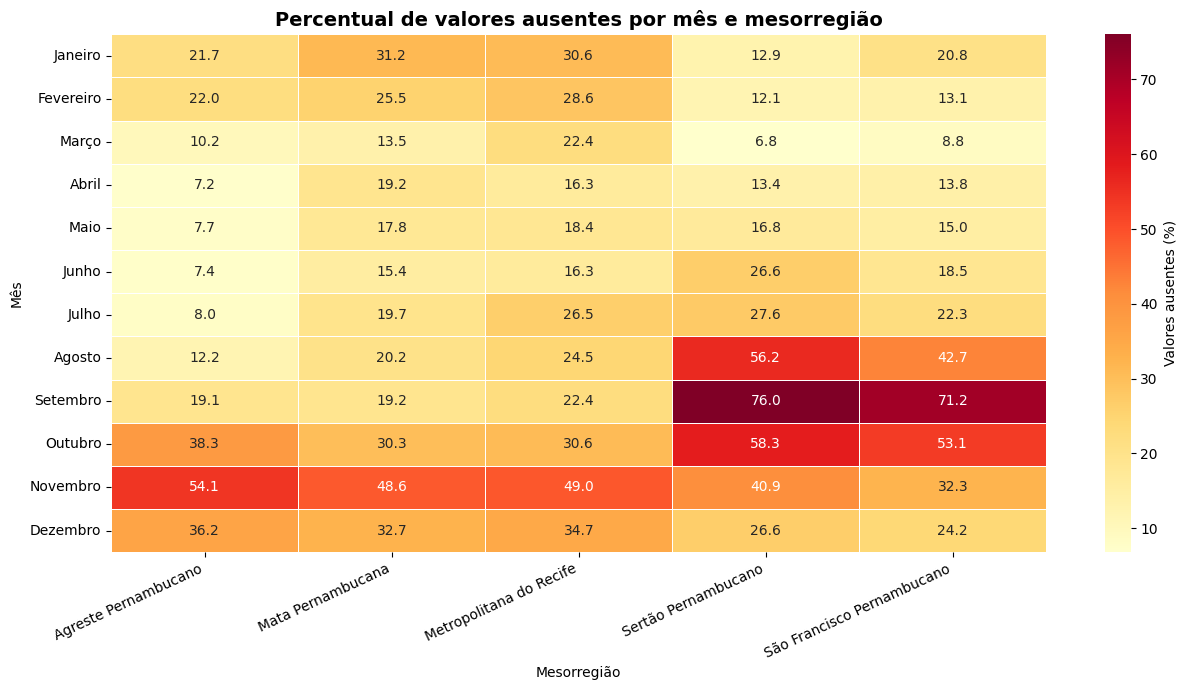

In [10]:
plt.figure(figsize=(13, 7))

sns.heatmap(
    tabela_regioes,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Valores ausentes (%)"}
)

plt.title(
    "Percentual de valores ausentes por mês e mesorregião",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Mesorregião")
plt.ylabel("Mês")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [11]:
# Contar valores iguais a zero
quantidade_zeros = (df[meses] == 0).sum().sum()

# Encontrar o menor valor observado
menor_valor = df[meses].min().min()

# Contar medições válidas
valores_validos = df[meses].count().sum()

print(f"Quantidade de valores zero: {quantidade_zeros}")
print(f"Menor precipitação registrada: {menor_valor} mm")
print(f"Total de medições válidas: {valores_validos}")

Quantidade de valores zero: 0
Menor precipitação registrada: 0.1 mm
Total de medições válidas: 35939


### Discussão preliminar dos mecanismos de ausência

A análise identificou 35.939 medições numéricas válidas, sem nenhuma ocorrência de precipitação igual a zero. O menor valor observado foi de 0,1 mm.

Além disso, os percentuais de ausência apresentaram diferenças expressivas entre meses e mesorregiões. No Sertão Pernambucano, por exemplo, setembro apresentou 76,03% de ausência entre os registros parcialmente preenchidos, enquanto no Agreste o percentual foi de 19,07%.

Esses resultados sugerem que os valores ausentes não estão distribuídos uniformemente no conjunto de dados.

A hipótese de ausência completamente aleatória (MCAR) torna-se menos plausível, embora não tenha sido formalmente rejeitada. O mecanismo MAR é uma possibilidade, considerando a associação das ausências com características observadas, como o mês e a localização.

Também existe a hipótese de um mecanismo MNAR, caso os hífens estejam relacionados à própria precipitação não observada, especialmente em meses sem chuva.

Entretanto, os dados disponíveis não permitem identificar definitivamente o mecanismo de ausência. A confirmação do significado do hífen junto à APAC permanece necessária.

Diante dessa incerteza, serão realizados experimentos comparando diferentes estratégias de imputação, incluindo mediana, KNNImputer e preenchimento com zero.

In [12]:
# Comparar a contagem original com a calculada
df["Meses ausentes"] = pd.to_numeric(
    df["Meses ausentes"],
    errors="coerce"
)

divergencias = df[
    df["Meses ausentes"] != df["qtd_ausentes"]
]

print("Total de registros:", len(df))
print("Registros com divergência:", len(divergencias))

display(
    divergencias[
        ["Código", "Posto", "Ano", "Meses ausentes", "qtd_ausentes"]
    ].head(10)
)

Total de registros: 5104
Registros com divergência: 1


,Código,Posto,Ano,Meses ausentes,qtd_ausentes
12,116,Altinho,2010,11,12


In [13]:
registro_altinho = df[
    (df["Código"] == 116) &
    (df["Ano"] == 2010)
]

display(
    registro_altinho[
        ["Posto", "Ano"] + meses +
        ["Meses ausentes", "qtd_ausentes"]
    ]
)

,Posto,Ano,Janeiro,Fevereiro,Março,Abril,Maio,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro,Meses ausentes,qtd_ausentes
12,Altinho,2010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,12


### Verificação de consistência dos valores ausentes

Foi realizada uma comparação entre a coluna original `Meses ausentes` e a contagem de valores ausentes calculada diretamente a partir das 12 colunas mensais.

Dos 5.104 registros analisados, apenas um apresentou divergência: o posto Altinho (código 116), no ano de 2010.

Nesse registro, a coluna original informa 11 meses ausentes, enquanto a análise das medições mensais identifica 12 valores ausentes.

Para garantir consistência e reprodutibilidade, adotou-se a variável `qtd_ausentes`, calculada a partir das colunas mensais, como referência para os filtros e experimentos.

O registro original foi preservado, e a divergência foi documentada como uma inconsistência de qualidade dos dados.

In [14]:
print("Códigos únicos:", df["Código"].nunique())
print("Nomes de postos únicos:", df["Posto"].nunique())

print(
    "Combinações únicas de código e posto:",
    df[["Código", "Posto"]].drop_duplicates().shape[0]
)

# Verificar códigos associados a diferentes nomes
nomes_por_codigo = df.groupby("Código")["Posto"].nunique()

print(
    "Códigos associados a mais de um nome:",
    (nomes_por_codigo > 1).sum()
)

Códigos únicos: 319
Nomes de postos únicos: 310
Combinações únicas de código e posto: 319
Códigos associados a mais de um nome: 0


### Verificação dos identificadores dos postos pluviométricos

A análise identificou 319 códigos únicos de postos pluviométricos e 310 nomes distintos. Foram encontradas 319 combinações únicas entre código e nome, sem ocorrência de códigos associados a múltiplos nomes.

Essa diferença indica que determinados nomes são compartilhados por mais de um código de posto.

Para manter a consistência com a metodologia de modelagem do grupo, o código do posto será utilizado como variável de agrupamento na validação cruzada.

A equivalência entre códigos distintos e estações físicas independentes não foi verificada nesta etapa.

In [15]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer, f1_score

# Configuração oficial da validação
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configuração do KNN da base v1
modelo_knn = {
    "n_neighbors": 3,
    "weights": "distance",
    "metric": "manhattan"
}

print("Ambiente dos experimentos configurado!")

Ambiente dos experimentos configurado!


In [21]:
def avaliar_estrategia(df, imputador, max_ausentes=6):

    # 1. Filtrar registros com base nos meses ausentes
    qtd = df[meses].isna().sum(axis=1)

    if max_ausentes is None:
        filtro = qtd < 12
    else:
        filtro = (qtd <= max_ausentes) & (qtd < 12)

    dados = df.loc[filtro].copy()

    # 2. Separar atributos, alvo e grupos
    X = dados[meses]
    y = dados["Mesorregiao"]
    grupos = dados["Código"]

    # 3. Pipeline para evitar vazamento de dados
    pipeline = Pipeline([
        ("imputador", imputador),
        ("normalizador", StandardScaler()),
        ("knn", KNeighborsClassifier(**modelo_knn))
    ])

    # 4. Verificar separação dos postos em cada fold
    for treino, teste in cv.split(X, y, groups=grupos):

        postos_treino = set(grupos.iloc[treino])
        postos_teste = set(grupos.iloc[teste])

        assert postos_treino.isdisjoint(postos_teste), (
            "ERRO: Vazamento de postos entre treino e validação!"
        )

    # 5. Avaliar com validação cruzada agrupada
    resultados = cross_validate(
        pipeline,
        X,
        y,
        groups=grupos,
        cv=cv,
        scoring={
            "f1_macro": "f1_macro",
            "f1_sf": make_scorer(
                f1_score,
                labels=["São Francisco Pernambucano"],
                average="macro",
                zero_division=0
            )
        },
        n_jobs=-1,
        error_score="raise"
    )

    # 6. Retornar métricas
    return {
        "n_instancias": len(X),
        "f1_macro": resultados["test_f1_macro"].mean(),
        "f1_std": resultados["test_f1_macro"].std(),
        "f1_sf": resultados["test_f1_sf"].mean()
    }

In [22]:
estrategias = {
    "Mediana": SimpleImputer(strategy="median"),
    "KNNImputer": KNNImputer(n_neighbors=5),
    "Zero": SimpleImputer(strategy="constant", fill_value=0)
}

resultados_iniciais = []

for nome, imputador in estrategias.items():

    resultado = avaliar_estrategia(
        df,
        imputador,
        max_ausentes=6
    )

    resultado["estrategia"] = nome
    resultados_iniciais.append(resultado)

comparacao_inicial = pd.DataFrame(resultados_iniciais)

display(
    comparacao_inicial[
        ["estrategia", "n_instancias", "f1_macro", "f1_std", "f1_sf"]
    ].round(4)
)

,estrategia,n_instancias,f1_macro,f1_std,f1_sf
0,Mediana,3337,0.7100,0.0209,0.5110
1,KNNImputer,3337,0.7259,0.0302,0.5627
2,Zero,3337,0.7369,0.0287,0.5526


In [23]:
limites = [4, 6, 8, 10]
resultados_finais = []

for limite in limites:
    for nome, imputador in estrategias.items():

        resultado = avaliar_estrategia(
            df,
            imputador,
            max_ausentes=limite
        )

        resultado["limite"] = limite
        resultado["estrategia"] = nome

        resultados_finais.append(resultado)

comparacao_final = pd.DataFrame(resultados_finais)

display(
    comparacao_final[
        ["limite", "estrategia", "n_instancias",
         "f1_macro", "f1_std", "f1_sf"]
    ].round(4)
)

,limite,estrategia,n_instancias,f1_macro,f1_std,f1_sf
0,4,Mediana,3086,0.7151,0.0230,0.5311
1,4,KNNImputer,3086,0.7288,0.0302,0.5734
2,4,Zero,3086,0.7476,0.0224,0.6126
3,6,Mediana,3337,0.7100,0.0209,0.5110
4,6,KNNImputer,3337,0.7259,0.0302,0.5627
5,6,Zero,3337,0.7369,0.0287,0.5526
6,8,Mediana,3428,0.6860,0.0550,0.4970
7,8,KNNImputer,3428,0.6739,0.0481,0.4460
8,8,Zero,3428,0.6988,0.0531,0.4838
9,10,Mediana,3488,0.6885,0.0197,0.4951


In [25]:
from sklearn.compose import ColumnTransformer

def avaliar_com_indicador(df, imputador, max_ausentes=4):

    qtd = df[meses].isna().sum(axis=1)
    filtro = (qtd < 12) & (qtd <= max_ausentes)
    dados = df.loc[filtro].copy()

    X = dados[meses].copy()
    X["qtd_ausentes"] = X[meses].isna().sum(axis=1)

    y = dados["Mesorregiao"]
    grupos = dados["Código"]

    preprocessamento = ColumnTransformer([
        ("chuva", Pipeline([
            ("imputador", imputador),
            ("normalizador", StandardScaler())
        ]), meses),
        ("ausencias", StandardScaler(), ["qtd_ausentes"])
    ])

    pipeline = Pipeline([
        ("preprocessamento", preprocessamento),
        ("knn", KNeighborsClassifier(**modelo_knn))
    ])

    resultados = cross_validate(
        pipeline,
        X,
        y,
        groups=grupos,
        cv=cv,
        scoring={
            "f1_macro": "f1_macro",
            "f1_sf": make_scorer(
                f1_score,
                labels=["São Francisco Pernambucano"],
                average="macro",
                zero_division=0
            )
        },
        n_jobs=-1,
        error_score="raise"
    )

    return {
        "n_instancias": len(X),
        "f1_macro": resultados["test_f1_macro"].mean(),
        "f1_std": resultados["test_f1_macro"].std(),
        "f1_sf": resultados["test_f1_sf"].mean()
    }

In [26]:
resultados_indicador = []

for nome, imputador in estrategias.items():

    resultado = avaliar_com_indicador(
        df,
        imputador,
        max_ausentes=4
    )

    resultados_indicador.append({
        "estrategia": nome,
        "indicador": "Com indicador",
        **resultado
    })

# Resultados anteriores, sem o indicador
sem_indicador = comparacao_final[
    comparacao_final["limite"] == 4
].copy()

sem_indicador["indicador"] = "Sem indicador"

# Juntar as duas avaliações
comparacao_indicador = pd.concat([
    sem_indicador,
    pd.DataFrame(resultados_indicador)
], ignore_index=True)

display(
    comparacao_indicador[
        ["estrategia", "indicador", "n_instancias",
         "f1_macro", "f1_std", "f1_sf"]
    ].round(4)
)

,estrategia,indicador,n_instancias,f1_macro,f1_std,f1_sf
0,Mediana,Sem indicador,3086,0.7151,0.0230,0.5311
1,KNNImputer,Sem indicador,3086,0.7288,0.0302,0.5734
2,Zero,Sem indicador,3086,0.7476,0.0224,0.6126
3,Mediana,Com indicador,3086,0.7079,0.0247,0.5207
4,KNNImputer,Com indicador,3086,0.7211,0.0277,0.5635
5,Zero,Com indicador,3086,0.7206,0.0184,0.5573


In [27]:
resultados_sem_limite = []

for nome, imputador in estrategias.items():
    resultado = avaliar_estrategia(
        df,
        imputador,
        max_ausentes=None
    )

    resultado["estrategia"] = nome
    resultados_sem_limite.append(resultado)

comparacao_sem_limite = pd.DataFrame(resultados_sem_limite)

display(
    comparacao_sem_limite[
        ["estrategia", "n_instancias",
         "f1_macro", "f1_std", "f1_sf"]
    ].round(4)
)

,estrategia,n_instancias,f1_macro,f1_std,f1_sf
0,Mediana,3542,0.6646,0.0350,0.4393
1,KNNImputer,3542,0.6623,0.0375,0.4262
2,Zero,3542,0.6996,0.0333,0.4842


In [28]:
# Consolidar os experimentos
tabela_final = comparacao_final.copy()

sem_limite = comparacao_sem_limite.copy()
sem_limite["limite"] = "Sem limite"

tabela_final["limite"] = tabela_final["limite"].astype(str)

tabela_final = pd.concat(
    [tabela_final, sem_limite],
    ignore_index=True
)

tabela_final = tabela_final[
    ["limite", "estrategia", "n_instancias",
     "f1_macro", "f1_std", "f1_sf"]
]

display(tabela_final.round(4))

# Exportar resultados
tabela_final.to_csv(
    "comparacao_imputacao.csv",
    index=False
)

print("Tabela consolidada salva!")

,limite,estrategia,n_instancias,f1_macro,f1_std,f1_sf
0,4,Mediana,3086,0.7151,0.0230,0.5311
1,4,KNNImputer,3086,0.7288,0.0302,0.5734
2,4,Zero,3086,0.7476,0.0224,0.6126
3,6,Mediana,3337,0.7100,0.0209,0.5110
4,6,KNNImputer,3337,0.7259,0.0302,0.5627
5,6,Zero,3337,0.7369,0.0287,0.5526
6,8,Mediana,3428,0.6860,0.0550,0.4970
7,8,KNNImputer,3428,0.6739,0.0481,0.4460
8,8,Zero,3428,0.6988,0.0531,0.4838
9,10,Mediana,3488,0.6885,0.0197,0.4951


Tabela consolidada salva!


In [39]:
# Teste de sensibilidade: agrupamento pelo nome do posto

dados_teste = df.copy()

for mes in meses:
    dados_teste[mes] = pd.to_numeric(
        dados_teste[mes].astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

qtd = dados_teste[meses].isna().sum(axis=1)
dados_teste = dados_teste.loc[qtd <= 4].copy()

dados_teste["Cidade"] = dados_teste["Posto"].apply(extrair_cidade)
dados_teste["Mesorregiao"] = dados_teste["Cidade"].map(meso_map)

X = dados_teste[meses]
y = dados_teste["Mesorregiao"]
grupos_nome = dados_teste["Posto"]

assert len(X) == 3086
assert y.notna().all()

pipeline_nome = Pipeline([
    ("imputador", SimpleImputer(strategy="constant", fill_value=0)),
    ("normalizador", StandardScaler()),
    ("knn", KNeighborsClassifier(**modelo_knn))
])

for treino, teste in cv.split(X, y, groups=grupos_nome):
    assert set(grupos_nome.iloc[treino]).isdisjoint(
        set(grupos_nome.iloc[teste])
    )

resultado_nome = cross_validate(
    pipeline_nome,
    X,
    y,
    groups=grupos_nome,
    cv=cv,
    scoring={
        "f1_macro": "f1_macro",
        "f1_sf": make_scorer(
            f1_score,
            labels=["São Francisco Pernambucano"],
            average="macro",
            zero_division=0
        )
    },
    n_jobs=-1,
    error_score="raise"
)

print("Instâncias:", len(X))
print("F1-macro:", round(resultado_nome["test_f1_macro"].mean(), 4))
print("F1-std:", round(resultado_nome["test_f1_macro"].std(), 4))
print("F1-SF:", round(resultado_nome["test_f1_sf"].mean(), 4))

Instâncias: 3086
F1-macro: 0.738
F1-std: 0.0348
F1-SF: 0.5834


## Conclusões e recomendação

Foram avaliadas três estratégias de tratamento de valores ausentes (mediana, KNNImputer e preenchimento por zero), considerando limites de 4, 6, 8 e 10 meses ausentes, além de um cenário sem limite adicional, com exclusão dos registros inteiramente vazios.

A imputação por zero apresentou o maior F1-macro em todos os limites avaliados. O melhor resultado observado foi **0,7476**, utilizando o limite de 4 meses ausentes, com 3.086 instâncias e F1 de 0,6126 para a mesorregião São Francisco Pernambucano.

A inclusão da quantidade de meses ausentes como atributo adicional não melhorou o F1-macro em nenhuma das três estratégias avaliadas com limite de 4 meses.

Os resultados sugerem que registros com muitas ausências podem dificultar a classificação. Entretanto, diferentes limites modificam o conjunto de instâncias avaliadas, impedindo atribuir as diferenças exclusivamente ao tratamento dos dados ausentes.

### Recomendação

A configuração com preenchimento por zero e limite de 4 meses é a principal candidata para avaliação adicional, por apresentar o maior F1-macro nos experimentos realizados.

Contudo, não há confirmação de que o símbolo `-` represente precipitação igual a zero. Portanto, o preenchimento por zero deve ser interpretado como uma estratégia de modelagem, e não como uma correção comprovada dos dados originais.

Recomenda-se manter o KNNImputer com limite de 6 meses como referência da base v1 e validar a configuração candidata em uma avaliação independente, com separação por posto, antes de substituí-la definitivamente.

Todos os experimentos utilizaram validação cruzada agrupada por código do posto, com imputação e normalização realizadas dentro do Pipeline para evitar vazamento de dados. O desempenho da melhor configuração foi selecionado na própria validação cruzada e não constitui uma estimativa independente de generalização.

### Análise de sensibilidade ao agrupamento

Durante a investigação, foram identificados nove nomes de postos associados a códigos distintos. Essa situação representa uma possível limitação da validação agrupada por código, pois não foi possível confirmar se os identificadores correspondem a estações físicas independentes.

Para avaliar a sensibilidade dos resultados, repetiu-se a configuração de melhor desempenho utilizando o nome do posto como identificador de agrupamento, mantendo as mesmas 3.086 instâncias e os mesmos hiperparâmetros.

| Métrica | Agrupamento por código | Agrupamento por nome |
|---|---:|---:|
| F1-macro | 0,7476 | 0,7380 |
| F1-std | 0,0224 | 0,0348 |
| F1-São Francisco | 0,6126 | 0,5834 |

A diferença de 0,0096 no F1-macro indica que o desempenho global permaneceu relativamente próximo, embora tenha apresentado uma pequena redução com o agrupamento por nome. O aumento do desvio-padrão e a redução do F1-São Francisco também indicam sensibilidade à composição dos folds.

Os resultados não comprovam a ausência de vazamento de dados, mas sugerem que a mudança no critério de agrupamento não provocou uma grande alteração no desempenho global do modelo. Recomenda-se verificar a identidade física dos postos caso o modelo seja utilizado em aplicações futuras.